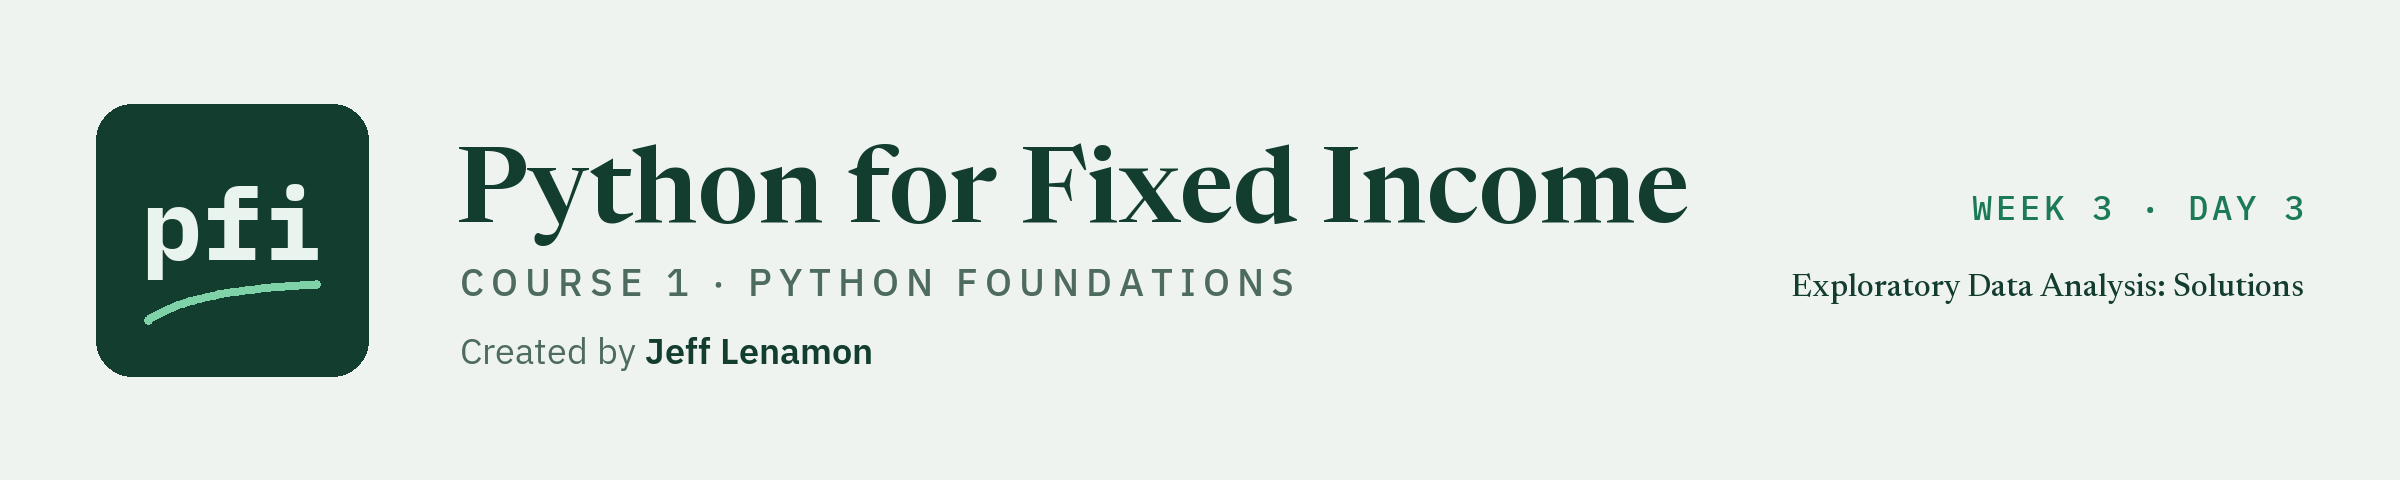

# Exploratory Data Analysis: Solutions

Week 3, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day3/13_exploratory_data_analysis_solutions.ipynb)

## Exercises

These are the worked answers; the issuers are invented.
Run the next two cells first: the first defines `check`; the second loads the files and defines the lesson's `clean_holdings`.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the house theme, the two files, and the lesson's clean_holdings, written out here
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
if os.path.exists('../../../data/holdings_messy.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
raw = pd.read_csv(data_folder + 'holdings_messy.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')


def clean_holdings(raw, ratings):
    book = raw.copy()
    for column in ['as_of_date', 'maturity', 'price_date']:
        book[column] = pd.to_datetime(book[column], format='%Y-%m-%d', errors='coerce')
        assert book[column].notna().all(), column + ' holds a date that could not be read'
    book = book.drop_duplicates().reset_index(drop=True)
    book['ticker'] = book['ticker'].str.strip().str.upper()
    book = pd.merge(book, ratings, on='rating', how='left', validate='many_to_one')
    book['bucket'] = book['bucket'].fillna('Not rated')
    book['grade'] = book['grade'].fillna('Not rated')
    q1, q3 = book['yield_pct'].quantile(0.25), book['yield_pct'].quantile(0.75)
    low = book['yield_pct'] < q1 - 1.5 * (q3 - q1)
    book.loc[low, 'yield_pct'] = (book.loc[low, 'yield_pct'] * 100).round(3)
    return book


book = clean_holdings(raw, ratings)
print(raw.shape, book.shape, book['market_value'].sum())

(204, 19) (200, 22) 490819215.0


### Exercise 1

Q. Apply the IQR rule to `price`. How many bonds fall below the lower limit and above the upper? Store the counts in **ex1_below** and **ex1_above**, then say from their other columns whether they look like errors or real extremes.

In [3]:
# the quartiles, the IQR, and the two limits
q1, q3 = book['price'].quantile(0.25), book['price'].quantile(0.75)
lower_limit, upper_limit = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print('Limits:', round(lower_limit, 3), round(upper_limit, 3))
ex1_below = (book['price'] < lower_limit).sum()
ex1_above = (book['price'] > upper_limit).sum()
print('Below:', ex1_below, '| above:', ex1_above)
# the flagged bonds, with the columns that can confirm or contradict a price
flagged = book[(book['price'] < lower_limit) | (book['price'] > upper_limit)]
flagged[['ticker', 'rating', 'coupon', 'price', 'yield_pct', 'oas', 'duration']].sort_values('price')

Limits: 83.344 114.8
Below: 4 | above: 4


,ticker,rating,coupon,price,yield_pct,oas,duration
17,CLDB,B,9.500,62.045,18.734,1446,4.513
117,NEVX,BBB-,3.875,73.873,6.080,153,12.898
150,SYLX,NaN,3.625,76.903,5.173,59,16.042
108,MULN,BB,3.875,81.455,6.265,189,8.324
76,GRON,A,7.250,116.795,5.116,76,7.303
146,SKEY,BBB,7.875,117.164,6.506,193,12.065
90,KEZA,A-,7.750,118.201,5.707,128,8.216
123,PLEA,AA,7.250,119.131,4.706,38,6.994


The limits are 83.344 and 114.8: 4 bonds below and 4 above.
The lowest, CLDB at 62.045, carries 1,446 bp and an 18.734 percent yield: one of the lesson's fourteen, and its columns agree.
The other three low prices are low coupons on long bonds, 3.875 percent or less over 8.3 to 16 years, which price well below 100 with no wide spread.
The four high prices have coupons of 7.25 to 7.875 percent against yields of 4.7 to 6.5.
Every one is explained by its other columns: real extremes, and they stay.

In [4]:
check('Exercise 1 below', ex1_below, 4)
check('Exercise 1 above', ex1_above, 4)

Exercise 1 below: correct
Exercise 1 above: correct


### Exercise 2

Q. If the five unrated bonds were dropped with `dropna(subset=['rating'])`, which sector would lose the most market value, and how much? Store them in **ex2_sector** and **ex2_lost**.

In [5]:
# market value by sector with every bond, and with the unrated bonds dropped
all_bonds = book.groupby('sector')['market_value'].sum()
rated_only = book.dropna(subset=['rating']).groupby('sector')['market_value'].sum()
lost = (all_bonds - rated_only).sort_values(ascending=False)
ex2_sector = lost.idxmax()
ex2_lost = lost.max()
print(lost.head(5).to_dict())
print(ex2_sector, ex2_lost, round(ex2_lost / all_bonds[ex2_sector] * 100, 2), 'percent of the sector')

{'Materials': 9532157.5, 'Transportation': 3472875.0, 'Telecom': 1529605.0, 'Industrials': 807900.0, 'Energy': 0.0}
Materials 9532157.5 13.29 percent of the sector


Materials loses 9,532,157.5, two of the five bonds and 13.29 percent of the sector.
Three other sectors lose one bond each, and the rest nothing: the total is the lesson's 15,342,537.5.
Dropping rows does not shrink every group evenly, and a sector report would show it with no sign of why.

In [6]:
check('Exercise 2 sector', ex2_sector, 'Materials')
check('Exercise 2 lost', ex2_lost, 9532157.5)

Exercise 2 sector: correct
Exercise 2 lost: correct


### Exercise 3

Q. Describe `dts`: store its mean and median, to 2 places, in **ex3_mean** and **ex3_median**, and the bonds with a z-score above 3 in **ex3_count**. Draw its histogram with both marked.

In [7]:
ex3_mean = round(book['dts'].mean(), 2)
ex3_median = round(book['dts'].median(), 2)
# one z-score per bond, then the bonds above 3
z = (book['dts'] - book['dts'].mean()) / book['dts'].std()
ex3_count = (z > 3).sum()
print('Mean:', ex3_mean, '| median:', ex3_median, '| skew:', round(book['dts'].skew(), 2), '| above 3:', ex3_count)
print(book.loc[z > 3, ['ticker', 'rating', 'duration', 'oas', 'dts']])
print(book.loc[[book['oas'].idxmax()], ['ticker', 'rating', 'duration', 'oas', 'dts']])

Mean: 1133.22 | median: 811.0 | skew: 1.95 | above 3: 6
    ticker rating  duration   oas     dts
17    CLDB      B     4.513  1446  6525.8
18    CLDB      B     9.019   520  4689.9
66    FESR   CCC+     7.252   614  4452.7
72    GALX     B-     6.506   679  4417.6
111   NEVN     B-     6.120   719  4400.3
132   PRAN   CCC+     5.058   871  4405.5
   ticker rating  duration   oas     dts
65   FESR   CCC+     1.546  1551  2397.8


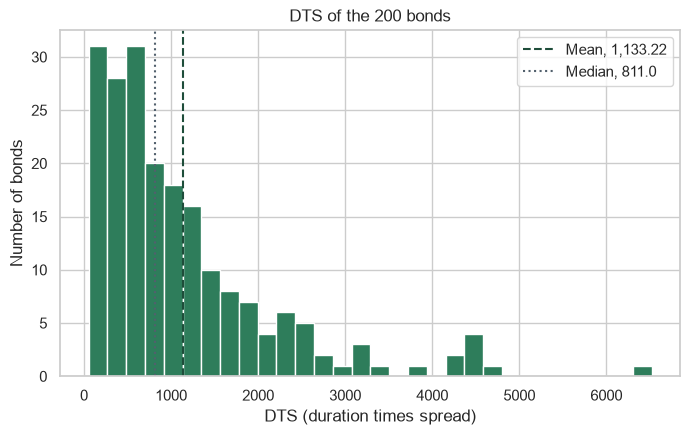

In [8]:
# the histogram with the mean and the median
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(book['dts'], bins=30)
ax.axvline(book['dts'].mean(), color='#1E4D3A', linestyle='--', label='Mean, 1,133.22')
ax.axvline(book['dts'].median(), color='#52606D', linestyle=':', label='Median, 811.0')
ax.legend()
ax.set_title('DTS of the 200 bonds')
ax.set_xlabel('DTS (duration times spread)')
ax.set_ylabel('Number of bonds')
plt.show()

The mean, 1,133.22, sits right of the median, 811.0, with a skew of 1.95: a tail on the right.
Six bonds have a z-score above 3, all rated B or lower.
The widest bond in the book, FESR at 1,551 bp, is not among them: its duration is 1.546 years, so its DTS is 2,397.8.
DTS is large only when duration and spread both are, so an outlier in one column need not be one in another.

In [9]:
check('Exercise 3 mean', ex3_mean, 1133.22)
check('Exercise 3 median', ex3_median, 811.0)
check('Exercise 3 count', ex3_count, 6)

Exercise 3 mean: correct
Exercise 3 median: correct
Exercise 3 count: correct


### Exercise 4

Q. What is the correlation of `coupon` and `price` for all 200 bonds, for Investment Grade, and for High Yield? Store each, to 2 places, in **ex4_all**, **ex4_ig**, and **ex4_hy**, and draw the two grades side by side.

In [10]:
ig = book[book['grade'] == 'Investment Grade']
hy = book[book['grade'] == 'High Yield']
ex4_all = round(book['coupon'].corr(book['price']), 2)
ex4_ig = round(ig['coupon'].corr(ig['price']), 2)
ex4_hy = round(hy['coupon'].corr(hy['price']), 2)
print('All:', ex4_all, '| Investment Grade:', ex4_ig, '| High Yield:', ex4_hy)

All: 0.31 | Investment Grade: 0.81 | High Yield: 0.07


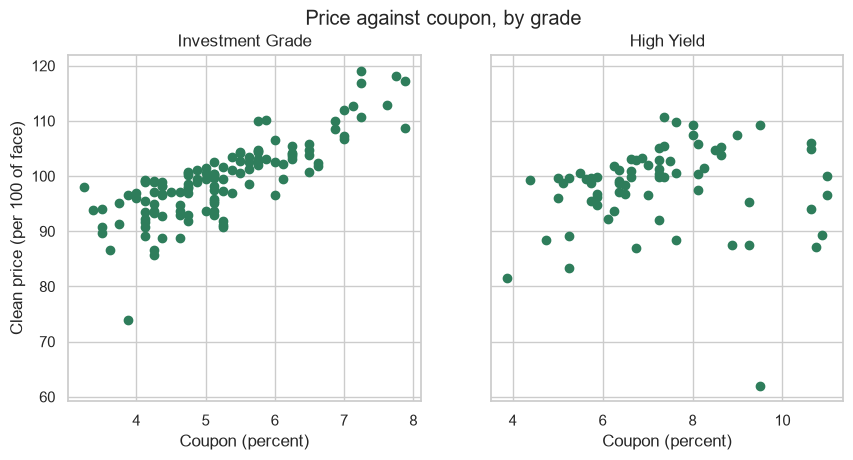

In [11]:
# two panels on one y axis
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, part, name in zip(axes, [ig, hy], ['Investment Grade', 'High Yield']):
    ax.scatter(part['coupon'], part['price'])
    ax.set_title(name)
    ax.set_xlabel('Coupon (percent)')
axes[0].set_ylabel('Clean price (per 100 of face)')
fig.suptitle('Price against coupon, by grade')
plt.show()

0.81 within Investment Grade, a clear rising band; 0.07 within High Yield, where credit sets the price.
The book's 0.31 describes neither: one correlation for a mixed table averages different relationships.

In [12]:
check('Exercise 4 all bonds', ex4_all, 0.31)
check('Exercise 4 Investment Grade', ex4_ig, 0.81)
check('Exercise 4 High Yield', ex4_hy, 0.07)

Exercise 4 all bonds: correct
Exercise 4 Investment Grade: correct
Exercise 4 High Yield: correct


### Exercise 5

Q. Write `clean_and_flag(raw, ratings)`: it calls `clean_holdings`, adds a column `stale_price`, True where the price date is before the as-of date, and asserts with a message that no CUSIP appears twice. Replace `return ...` with your code, then store its result on `raw` in **ex5_book**.

In [13]:
def clean_and_flag(raw, ratings):
    # the day's decisions, by calling the function that holds them
    book = clean_holdings(raw, ratings)
    # the new flag
    book['stale_price'] = book['price_date'] < book['as_of_date']
    # the new check: a CUSIP still there twice stops the function
    repeats = book['cusip'].duplicated().sum()
    assert repeats == 0, f'CUSIPs still repeated after cleaning: {repeats}'
    return book


ex5_book = clean_and_flag(raw, ratings)
print(ex5_book.shape[1], 'columns |', ex5_book['stale_price'].sum(), 'flagged |',
      ex5_book.loc[ex5_book['stale_price'], 'market_value'].sum())

23 columns | 6 flagged | 13342347.5


23 columns, the lesson's 22 and the flag; 6 bonds flagged, worth the lesson's 13,342,347.5.
The function calls `clean_holdings` rather than repeating it, so a change to the cleaning is made in one place.
The check below sends one CUSIP on two rows that differ, which `drop_duplicates()` keeps, and the `assert` stops it.

In [14]:
if ex5_book is ... or ex5_book is None:
    check('Exercise 5', ex5_book, 23)
else:
    check('Exercise 5 columns', ex5_book.shape[1], 23)
    check('Exercise 5 stale prices', int(ex5_book['stale_price'].sum()), 6)
    # one CUSIP on two rows that differ: the function should stop on it
    broken = pd.concat([raw, raw.head(1).assign(par_held=1000)], ignore_index=True)
    try:
        clean_and_flag(broken, ratings)
        stopped = False
    except AssertionError as error:
        stopped = True
        print('Stopped with:', error)
    check('Exercise 5 the assert stops a repeated CUSIP', stopped, True)

Exercise 5 columns: correct
Exercise 5 stale prices: correct
Stopped with: CUSIPs still repeated after cleaning: 1
Exercise 5 the assert stops a repeated CUSIP: correct


### Exercise 6

Q. Run the lesson's fill test on `yield_pct`: in each of 100 draws blank 8 yields with `book.sample(8, random_state=seed)`, fill them with the column median and with the bucket median, and average the miss. Store the two averages, to 2 places, in **ex6_all** and **ex6_bucket**.

In [15]:
column_miss, bucket_miss = [], []
for seed in range(100):
    test = book.copy()
    blanked = test.sample(8, random_state=seed).index
    true = test.loc[blanked, 'yield_pct']
    test.loc[blanked, 'yield_pct'] = np.nan
    by_column = test['yield_pct'].fillna(test['yield_pct'].median())
    by_bucket = test['yield_pct'].fillna(test.groupby('bucket')['yield_pct'].transform('median'))
    column_miss.append((by_column[blanked] - true).abs().mean())
    bucket_miss.append((by_bucket[blanked] - true).abs().mean())
ex6_all = round(float(np.mean(column_miss)), 2)
ex6_bucket = round(float(np.mean(bucket_miss)), 2)
print('Column median:', ex6_all, '| bucket median:', ex6_bucket, 'percentage points of yield')

Column median: 1.07 | bucket median: 0.64 percentage points of yield


The bucket median misses by 0.64 points on average, the column median by 1.07.
Yield rises with spread and spread with the rating, so here the bucket helps, as it did for OAS and not for duration.
The test, one loop, is the point: it says whether a group fill is worth using on this column.

In [16]:
check('Exercise 6 column median', ex6_all, 1.07)
check('Exercise 6 bucket median', ex6_bucket, 0.64)

Exercise 6 column median: correct
Exercise 6 bucket median: correct


### Exercise 7: AI check

The lesson's numbers are 200 bonds, 490,819,215, and 185.75 bp; two are on the cover note.
The original code reported 195 bonds, 475,476,677.5, and 186.15 bp, with no error.
The bug is `data = data.dropna()`: it deletes every row with a gap in any column, and the only gaps are the five missing ratings, so five bonds the desk owns went.
Each number looks plausible on its own; the cover note caught it.
The fix deletes that line: a missing rating is a reason to label a bond, not to remove it.

In [17]:
# load the extract
data = pd.read_csv(data_folder + 'holdings_messy.csv')

# remove repeated rows
data = data.drop_duplicates()

# the rows with a missing rating stay: the bonds are real

ex7_bonds = len(data)
ex7_value = data['market_value'].sum()
ex7_oas = round(data['oas'].mean(), 2)
print('Bonds:', ex7_bonds, '| market value:', ex7_value, '| mean OAS:', ex7_oas)

Bonds: 200 | market value: 490819215.0 | mean OAS: 185.75


In [18]:
check('Exercise 7 bonds', ex7_bonds, 200)
check('Exercise 7 market value', ex7_value, 490819215.0)
check('Exercise 7 mean OAS', ex7_oas, 185.75)

Exercise 7 bonds: correct
Exercise 7 market value: correct
Exercise 7 mean OAS: correct
